# ver02 — 512-d cross-model mapping with 60 M models

Pipeline: `token(vi) → t5-small-vietnamese encoder → 512×512 map → t5-small decoder → token(en)`.

This notebook is the report of record for the numbers. It reads what the pipeline wrote; it does not
recompute it. The command that produced each artefact is printed above its cell.

## 0. Environment as measured

In [1]:
import json, sys, platform
from pathlib import Path
import numpy as np, pandas as pd, torch

ROOT = Path.cwd()
RES = ROOT / "results"
print(platform.platform(), "| python", sys.version.split()[0])
print("torch", torch.__version__, "cuda", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print("vram MB", torch.cuda.get_device_properties(0).total_memory // 2**20 if torch.cuda.is_available() else 0)

Windows-11-10.0.26200-SP0 | python 3.12.10
torch 2.7.1+cu128 cuda True NVIDIA GeForce RTX 3050 Laptop GPU
vram MB 4095


## 1. Corpus and the 80/10/10 split

`python -m src.build_pairs`

In [2]:
man = json.loads((ROOT / "data" / "pairs_manifest.json").read_text(encoding="utf-8"))
print("rows:", f"{man['rows']:,}", "| dedup:", man["dedup"], "| id rule:", man["id_rule"])
print("lora shard (dirty, never in the map corpus):", man["lora_file"])
print("excluded prior artefacts:", list(man["excluded_from"]))
print(pd.Series(man["per_file"]).sort_index().to_string())

rows: 6,668,910 | dedup: per (file, vi) | id rule: row_number() OVER (ORDER BY md5(vi), file)
lora shard (dirty, never in the map corpus): train-00000-of-00014
excluded prior artefacts: ['scaled_100k', 'copy_lora_train_50k', 'copy_lora_eval_4k']
train-00000-of-00014    439869
train-00001-of-00014    479303
train-00002-of-00014    479445
train-00003-of-00014    479056
train-00004-of-00014    478790
train-00005-of-00014    479054
train-00006-of-00014    479242
train-00007-of-00014    479160
train-00008-of-00014    479394
train-00009-of-00014    479329
train-00010-of-00014    478878
train-00011-of-00014    478967
train-00012-of-00014    479182
train-00013-of-00014    479241


## 2. Coreset — which shard, and why

`python -m src.embed sentence_sample` then `python -m src.coreset`

In [3]:
cs = pd.read_csv(RES / "coreset.csv")
chosen = json.loads((ROOT / "data" / "chosen_shard.json").read_text(encoding="utf-8"))
print("chosen:", chosen["file"], "| rule:", chosen["rule"])
display(cs[cs.k == cs.k.min()].sort_values("score", ascending=False)
        .round(3).reset_index(drop=True))

chosen: train-00008-of-00014 | rule: max mean z-score of rep/diversity/outlier/coverage, K=4, top PC removed


,k,file,n,representativeness,diversity,outlier_rate,coverage,js,mean_dist,score,score_sd,eligible,chosen
0,4,train-00008-of-00014,50000,0.052,0.996,0.052,1.0,0.0,0.948,0.701,0.463,1,1
1,4,train-00004-of-00014,50000,0.052,0.996,0.051,1.0,0.0,0.948,0.641,0.440,1,0
2,4,train-00005-of-00014,50000,0.052,0.996,0.050,1.0,0.0,0.948,0.548,0.471,1,0
3,4,train-00007-of-00014,50000,0.051,0.997,0.050,1.0,0.0,0.949,0.188,0.446,1,0
4,4,train-00003-of-00014,50000,0.051,0.996,0.051,1.0,0.0,0.949,0.130,0.461,1,0
5,4,train-00002-of-00014,50000,0.052,0.995,0.051,1.0,0.0,0.948,-0.048,0.432,1,0
6,4,train-00012-of-00014,50000,0.051,0.996,0.050,1.0,0.0,0.949,-0.108,0.471,1,0
7,4,train-00009-of-00014,50000,0.052,0.996,0.049,1.0,0.0,0.948,-0.111,0.446,1,0
8,4,train-00010-of-00014,50000,0.052,0.996,0.049,1.0,0.0,0.948,-0.262,0.448,1,0
9,4,train-00001-of-00014,50000,0.051,0.996,0.050,1.0,0.0,0.949,-0.302,0.457,1,0


## 3. Ridge — 512 linear regressions, and the λ sweep

`python -m src.embed moments --file <shard>` then `python -m src.fit_ridge`

In [4]:
display(pd.read_csv(RES / "ridge_sweep.csv").round(6))
for d in ("vi_en", "en_vi"):
    m = np.load(ROOT / "data" / f"map_{d}.npz")
    print(d, "lambda", float(m["lam"]), "| pairs", f"{int(m['n_pairs']):,}",
          "| tokens", f"{int(m['n_tokens']):,}", "| W", m["W"].shape)

,direction,lambda,mse_train,mse_val
0,vi_en,0.0000,9.554770,9.557948
1,vi_en,0.0001,9.554770,9.557948
2,vi_en,0.0010,9.554770,9.557948
3,vi_en,0.0100,9.554770,9.557948
4,vi_en,0.1000,9.554770,9.557948
5,vi_en,1.0000,9.554770,9.557947
6,vi_en,10.0000,9.554770,9.557947
7,en_vi,0.0000,20.404354,16.970995
8,en_vi,0.0001,20.404354,16.970994
9,en_vi,0.0010,20.404354,16.970992


vi_en lambda 0.0 | pairs 383,516 | tokens 9,276,754 | W (512, 512)
en_vi lambda 10.0 | pairs 383,516 | tokens 9,276,754 | W (512, 512)


## 4. LightGBM vs ridge on identical tokens

`python -m src.fit_lgbm --tokens 120000 --threads 8`

In [5]:
lg = json.loads((RES / "lgbm_metrics.json").read_text(encoding="utf-8"))
print({k: lg[k] for k in ("n_tokens_train", "n_tokens_val", "r2_ridge_mean", "r2_lgbm_mean",
                          "token_mse_ridge", "token_mse_lgbm", "token_cosine_ridge",
                          "token_cosine_lgbm", "wall_min")})
display(pd.read_csv(RES / "lgbm_vs_ridge.csv").describe().round(4))

{'n_tokens_train': 90000, 'n_tokens_val': 10000, 'r2_ridge_mean': 0.09181181341409683, 'r2_lgbm_mean': 0.11599479409276553, 'token_mse_ridge': 8.860604286193848, 'token_mse_lgbm': 8.631148103839807, 'token_cosine_ridge': 0.4594803750514984, 'token_cosine_lgbm': 0.4775672186111904, 'wall_min': 38.1}


,dim,r2_ridge,r2_lgbm,delta,trees,features_used
count,512.0000,512.0000,512.0000,512.0000,512.0,512.0000
mean,255.5000,0.0918,0.1160,0.0242,150.0,457.2090
std,147.9459,0.0590,0.0661,0.0122,0.0,32.1941
min,0.0000,0.0294,0.0404,0.0070,150.0,324.0000
25%,127.7500,0.0515,0.0709,0.0173,150.0,441.0000
50%,255.5000,0.0704,0.0927,0.0215,150.0,471.0000
75%,383.2500,0.1159,0.1405,0.0283,150.0,480.0000
max,511.0000,0.3819,0.4308,0.1201,150.0,494.0000


## 5. Copy gate — can the decoder reproduce a vector it was given?

`python -m src.copy_gate eval --side en` then `... train --side en` then `... eval --adapter`

In [6]:
for side in ("en", "vi"):
    for tag in ("", "_lora"):
        p = RES / f"copy_gate_{side}{tag}.json"
        if p.exists():
            d = json.loads(p.read_text(encoding="utf-8"))
            print(f"{side:3s}{tag:6s} exact {d['exact_match']:.3f}  empty {d['empty_rate']:.3f}  "
                  f"words {d['mean_hyp_words']:.1f}/{d['mean_ref_words']:.1f}")

en        exact 0.096  empty 0.016  words 16.9/17.1
en _lora  exact 0.859  empty 0.000  words 17.2/17.1


## 6. Generation — five channels, one decoder

`python -m src.train_decoder --direction vi_en --pairs 80000` then `python -m src.generate` then `python -m src.score --comet`

In [7]:
for d in ("vi_en", "en_vi"):
    p = RES / f"metrics_{d}.json"
    if not p.exists():
        continue
    met = json.loads(p.read_text(encoding="utf-8"))
    rows = [{"channel": k, **v} for k, v in met.items() if isinstance(v, dict) and "bleu" in v]
    tbl = pd.DataFrame(rows).set_index("channel")
    cols = ["bleu", "bleu_ci95", "chrf", "comet", "mean_nll", "degenerate_rate", "empty_rate",
            "vi_word_rate", "mean_hyp_words"]
    print("==", d)
    display(tbl[[c for c in cols if c in tbl.columns]].round(4))
    for k, v in met.items():
        if k.startswith("paired_"):
            print(k, v)

== vi_en


,bleu,bleu_ci95,chrf,mean_nll,degenerate_rate,empty_rate,vi_word_rate,mean_hyp_words
channel,,,,,,,,
mapped,2.8446,"[2.578876007395305, 3.07556969281862]",19.9580,3.1968,0.1420,0.0000,0.0000,17.4863
lgbm,2.3237,"[1.9752523513404057, 2.911874495480503]",16.1100,3.3768,0.0590,0.0000,0.0000,12.8350
native,4.1656,"[3.6804877967634564, 4.660335734818094]",15.3529,3.3655,0.3157,0.0007,0.0030,16.1361
identity,0.0332,"[0.019226937702987376, 0.04436554726692712]",6.0906,4.6215,0.1557,0.0623,0.0014,8.6438
copy,0.3713,"[0.1461229133049844, 0.6028184678687242]",1.4975,10.5197,0.9510,0.0227,0.0000,24.0048


paired_lgbm_minus_mapped {'mean': -0.5117789310674358, 'ci95': [-0.9095613680506588, 0.09725478142168545], 'p_other_le_mapped': 0.96, 'n_boot': 300}
paired_native_minus_mapped {'mean': 1.3369106296158932, 'ci95': [0.7950775877662448, 1.9125122758277335], 'p_other_le_mapped': 0.0, 'n_boot': 300}
paired_identity_minus_mapped {'mean': -2.799588441599833, 'ci95': [-3.051984565356044, -2.5385214465424655], 'p_other_le_mapped': 1.0, 'n_boot': 300}
paired_copy_minus_mapped {'mean': -2.48955433895352, 'ci95': [-2.8164093002820434, -2.164946219182081], 'p_other_le_mapped': 1.0, 'n_boot': 300}
== en_vi


,bleu,bleu_ci95,chrf,mean_nll,degenerate_rate,empty_rate,vi_word_rate,mean_hyp_words
channel,,,,,,,,
mapped,2.9957,"[2.7540002401896446, 3.408377952688687]",15.6607,3.5400,0.1523,0.0000,0.8366,20.3140
native,3.5447,"[3.2938529179811913, 3.960667571105656]",15.5612,3.4826,0.1877,0.0007,0.8130,20.5037
identity,0.0717,"[0.05549064471042096, 0.10701362045593812]",8.6857,5.2197,0.5877,0.0023,0.7948,32.2857


paired_native_minus_mapped {'mean': 0.5624144894335797, 'ci95': [0.25485666345574964, 0.9731035849509503], 'p_other_le_mapped': 0.0, 'n_boot': 100}
paired_identity_minus_mapped {'mean': -2.9303368055645933, 'ci95': [-3.3384173418749956, -2.6769735574953195], 'p_other_le_mapped': 1.0, 'n_boot': 100}


### 6.1 Examples (same source, one row per channel)

In [8]:
import itertools
for d in ("vi_en",):
    gens = {c: [json.loads(l) for l in (RES / f"gen_{d}_{c}.jsonl").open(encoding="utf-8")]
            for c in ("mapped", "lgbm", "native", "identity", "copy")
            if (RES / f"gen_{d}_{c}.jsonl").exists()}
    for i in (0, 1, 2):
        print("SRC:", gens["mapped"][i]["src"])
        print("REF:", gens["mapped"][i]["ref"])
        for c, rows in gens.items():
            print(f"  {c:9s}: {rows[i]['hyp']}")
        print()

SRC: Tìm thêm các thông điệp dí dỏm (nhưng trong sạch) của tôi tại @ ABCPress. "
REF: Find more of my witty (but clean) tweets @ ABCPress. â€ Now that you have your basic information, edit it so it has some personality.
  mapped   : " I've got a lot of information about you, " said the spokesman.
  lgbm     : Find out what you're doing in the 's' section.
  native   : Then you can see the sex of the sex of the sex of the sex of the sex of the sex of the sex of the sex of the s
  identity : -
  copy     : . . . . . . . . . . . . . . . . . . . . . . . .

SRC: Điều này không có nghĩa là bạn không thể bàn về các vấn đề rắc rối, mà là bạn nên cố gắng giữ cho ngôn ngữ cũng như cách bạn trò chuyện mang tính tích cực.
REF: That doesn't mean you can't discuss problems.
  mapped   : This is because it is difficult to understand what is happening in the world, and it is difficult to understand what is happening in the world.
  lgbm     : This is not the only way to get the same thing done, but i

## 7. Representation geometry, with the controls that make cosine interpretable

`python -m src.eval_geometry --direction vi_en`

In [9]:
for d in ("vi_en", "en_vi"):
    p = RES / f"geometry_{d}.csv"
    if p.exists():
        print("==", d)
        display(pd.read_csv(p).round(4))

== vi_en


,direction,variant,token_cosine,token_mse,sentence_cosine,sentence_mse,retrieval_at_1,margin_mean,margin_frac_positive
0,vi_en,map,0.4429,9.5698,0.7641,1.4163,0.0884,-0.0629,0.0884
1,vi_en,identity,0.0906,33.9243,0.2700,6.6390,0.0040,-0.1099,0.0040
2,vi_en,mean,0.3542,10.4702,0.6671,1.8723,0.0002,-0.1399,0.0002
3,vi_en,lgbm,0.4388,9.5836,0.7332,1.5632,0.0556,-0.0663,0.0556


== en_vi


,direction,variant,token_cosine,token_mse,sentence_cosine,sentence_mse,retrieval_at_1,margin_mean,margin_frac_positive
0,en_vi,map,0.4792,16.2365,0.8113,2.1996,0.1803,-0.0476,0.1803
1,en_vi,identity,0.0989,31.1191,0.2731,6.8807,0.0053,-0.1203,0.0053
2,en_vi,mean,0.3933,17.9472,0.6950,3.2856,0.0003,-0.1602,0.0003


The identity row is the point: without a map the two spaces are nearly orthogonal. The mean row is the
trap: predicting the dataset mean earns cosine for free, which is why retrieval@1 carries the claim.

## 8. Neural mining (M1–M4)

`python -m src.mine`

In [10]:
print((RES / "mining.md").read_text(encoding="utf-8"))

# Neural-mining tables (generated by src/mine.py)

## M1 — nonlinearity gap (512 dims, identical token sample)

| metric | ridge | LightGBM |
|---|---|---|
| mean per-dim R² | 0.0918 | 0.1160 |
| token MSE | 8.8606 | 8.6311 |
| token cosine | 0.4595 | 0.4776 |

ΔR² mean +0.02418, median +0.02154; improved 100.0% of dims, worse 0.0%.
Trees/dim 150, features used/dim 457/512.

## M3 — decoder tolerance (mapped channel)

| channel | Pearson(cos, NLL) | Spearman | NLL by cos quartile (low→high cos) |
|---|---|---|---|
| vi_en mapped | +0.012 | +0.015 | 3.18, 3.19, 3.20, 3.22 |
| vi_en lgbm | +0.004 | +0.005 | 3.36, 3.42, 3.35, 3.38 |
| en_vi mapped | -0.005 | -0.008 | 3.55, 3.53, 3.55, 3.53 |

## M4 — layer-wise transfer (token cosine to the target's final state)

| direction | L0 | L1 | L2 | L3 | L4 | L5 | L6 |
|---|---|---|---|---|---|---|---|
| vi_en | 0.0237 | 0.0406 | 0.0757 | 0.0974 | 0.1075 | 0.0892 | 0.4425 |
| en_vi | 0.0532 | 0.1330 | 0.1646 | 0.1861 | 0.1941 | 0.1913 | 0.4793 |


## 9. Figures

fig_bleu.png


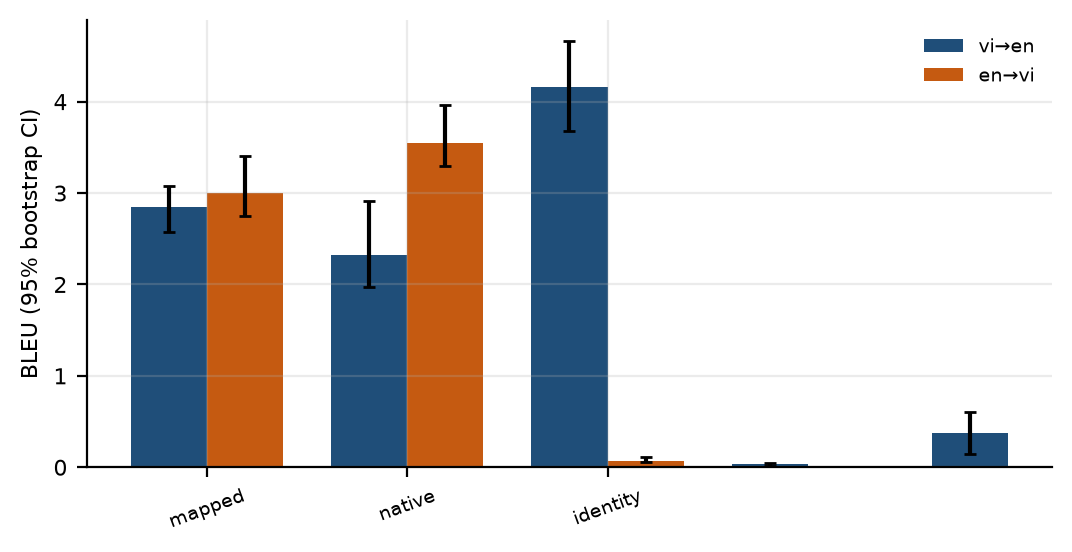

fig_coreset.png


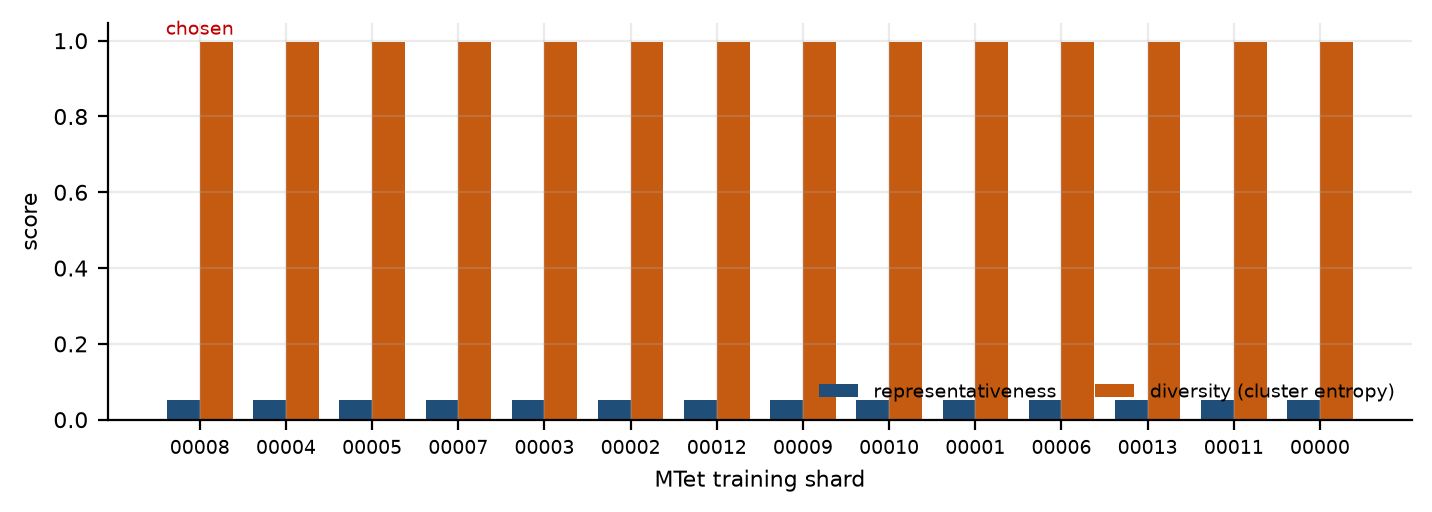

fig_layers.png


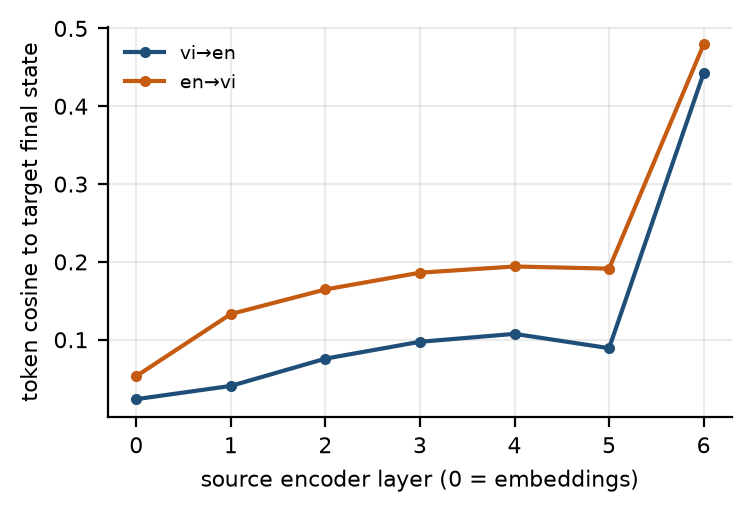

fig_r2_ridge_vs_lgbm.png


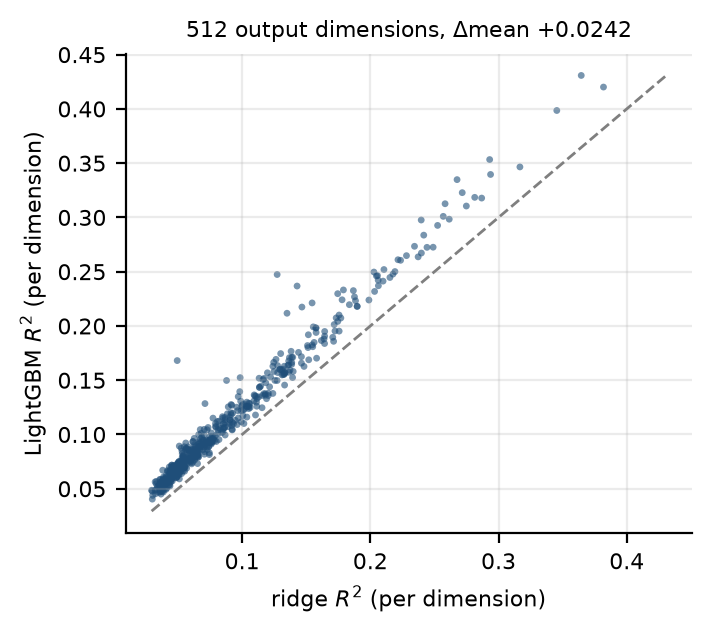

fig_ridge_sweep.png


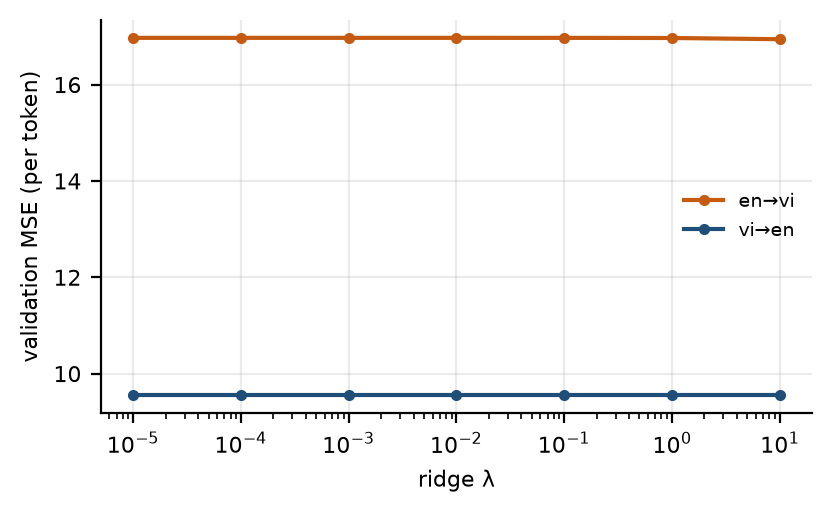

fig_tolerance.png


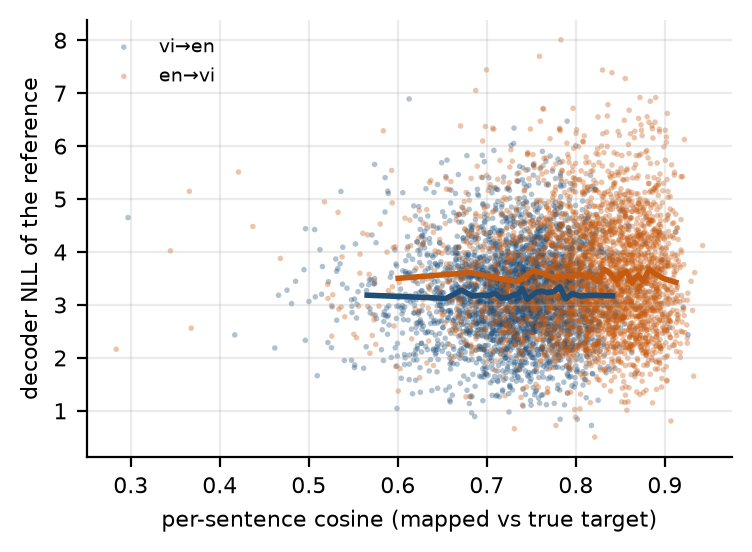

fig_training.png


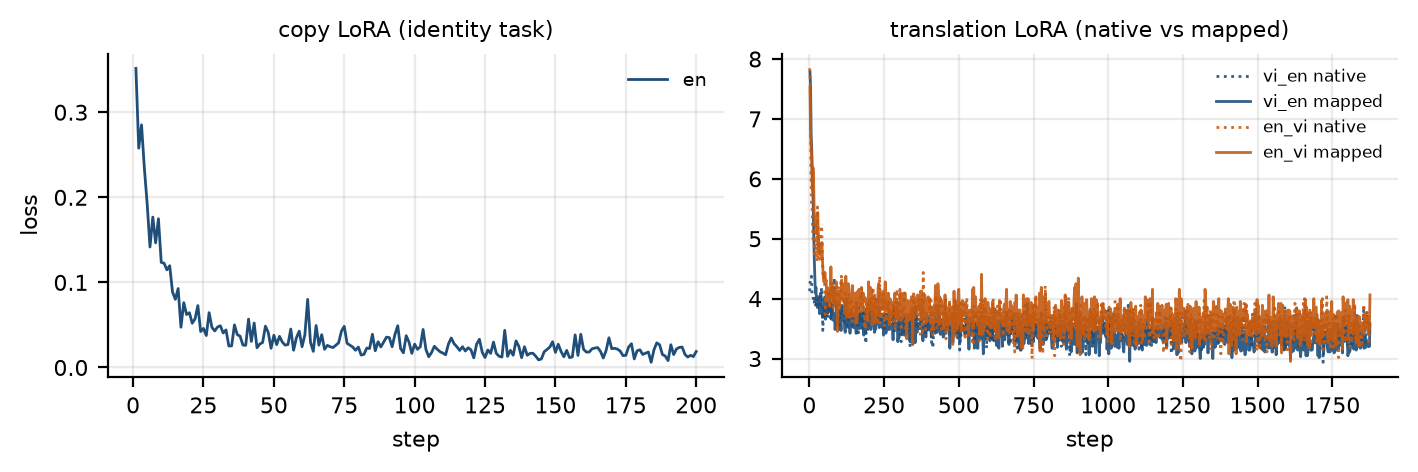

In [11]:
from IPython.display import Image, display as d2
for p in sorted((RES / "figures").glob("*.png")):
    print(p.name)
    d2(Image(filename=str(p), width=640))

## 10. What this does not show

* BLEU is measured on 5,000 test sentences of **one shard**; the shard was chosen for
  representativeness, but it is still one shard, and the 95 % CI does not cover shard variance.
* The decoder is 60 M and trained one epoch on 80 k pairs; the absolute BLEU ceiling is set by that,
  not by the map. The claim is the *gap between channels*, not the absolute number.
* `copy` is a readout diagnostic, not a translation system: it is trained with T_out = T_in and can
  learn a length-copy shortcut. Its BLEU is reported to be inspected, not to be trusted.
* COMET is scored on the first 2,000 sentences only (it runs at ~7 sent/s).